## Planning:
- Load data
- Create sample FE - sum of boolean and proportion of boolean and Digit Position
- Create TE in run.cv
- Implement for XGBoost

## Loading Data

In [1]:
import pandas as pd
import numpy as np

In [2]:
from pathlib import Path

In [3]:
current_dir = Path.cwd()
competition_root = current_dir.parents[1]

In [4]:
competition_path = competition_root/"One Dollar"

In [5]:
train = pd.read_csv(competition_path/"data/train.csv")
test = pd.read_csv(competition_path/"data/test.csv")
submit = pd.read_csv(competition_path/"data/sample_submission.csv")

In [6]:
train.shape

(15000, 13)

In [7]:
train.head()

,id,Hardness,allelectrons_Total,density_Total,allelectrons_Average,val_e_Average,atomicweight_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average
0,0,6.0,250.0,27.105990,12.0,4.8,25.408218,11.330440,2.757000,1.7000,0.945000,0.488270,1.00660
1,1,5.0,42.0,1.742832,8.0,3.5,17.790357,12.184250,2.727500,1.5450,0.710000,0.618493,0.65972
2,2,3.8,96.0,8.841328,9.5,3.0,19.397353,13.161829,2.788333,1.5450,0.723333,0.659870,1.23121
3,3,2.5,150.0,23.576975,50.0,4.0,167.400000,10.776008,2.240000,2.0150,1.180000,0.457615,7.77500
4,4,6.8,80.0,7.734660,10.0,5.0,20.255278,11.026725,2.790000,1.6725,0.852500,0.495275,1.02228


In [8]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     15000 non-null  int64  
 1   Hardness               15000 non-null  float64
 2   allelectrons_Total     15000 non-null  float64
 3   density_Total          15000 non-null  float64
 4   allelectrons_Average   15000 non-null  float64
 5   val_e_Average          15000 non-null  float64
 6   atomicweight_Average   15000 non-null  float64
 7   ionenergy_Average      15000 non-null  float64
 8   el_neg_chi_Average     15000 non-null  float64
 9   R_vdw_element_Average  15000 non-null  float64
 10  R_cov_element_Average  15000 non-null  float64
 11  zaratio_Average        15000 non-null  float64
 12  density_Average        15000 non-null  float64
dtypes: float64(12), int64(1)
memory usage: 1.5 MB


In [9]:
test.shape

(10000, 12)

## Data Visualisation

### Missing Value

In [10]:
# missing train
train_missing = pd.DataFrame(train.isna().sum()).reset_index()

In [11]:
train_missing

,index,0
0,id,0
1,Hardness,0
2,allelectrons_Total,0
3,density_Total,0
4,allelectrons_Average,0
5,val_e_Average,0
6,atomicweight_Average,0
7,ionenergy_Average,0
8,el_neg_chi_Average,0
9,R_vdw_element_Average,0


In [12]:
# missing test
test_missing = pd.DataFrame(test.isna().sum()).reset_index()

In [13]:
test_missing

,index,0
0,id,0
1,allelectrons_Total,0
2,density_Total,0
3,allelectrons_Average,0
4,val_e_Average,0
5,atomicweight_Average,0
6,ionenergy_Average,0
7,el_neg_chi_Average,0
8,R_vdw_element_Average,0
9,R_cov_element_Average,0


## Key Stats

In [30]:
train.describe()

,id,Hardness,allelectrons_Total,density_Total,allelectrons_Average,val_e_Average,atomicweight_Average,ionenergy_Average,el_neg_chi_Average,R_vdw_element_Average,R_cov_element_Average,zaratio_Average,density_Average
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7499.500000,4.421263,125.220709,13.168250,16.507343,4.447046,3.573151e+02,10.788980,2.547634,1.720777,0.941916,0.489042,1.896446
std,4330.271354,1.721446,302.337242,17.551363,10.805374,0.841425,3.931382e+04,1.835890,0.441645,0.272693,0.208014,0.081936,1.880060
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3749.750000,2.500000,63.750000,5.686908,10.000000,4.000000,2.018540e+01,10.398750,2.330000,1.672500,0.880000,0.476095,0.748760
50%,7499.500000,4.900000,99.000000,9.133000,12.000000,4.666667,2.478962e+01,11.177555,2.700400,1.738000,0.926000,0.489486,1.050950
75%,11249.250000,6.000000,126.000000,14.959782,21.750000,4.800000,4.798569e+01,11.684513,2.790000,1.870000,1.028000,0.496593,2.292800
max,14999.000000,10.000000,15300.000000,643.093804,116.000000,6.000000,4.814975e+06,15.245810,3.443000,2.280000,1.900000,0.825990,10.970000


### Data Distribution

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
data_viz = train.drop(columns = ["id"])

In [26]:
num_cols = train.drop(columns=["id"]).select_dtypes(include="number").columns.to_list()

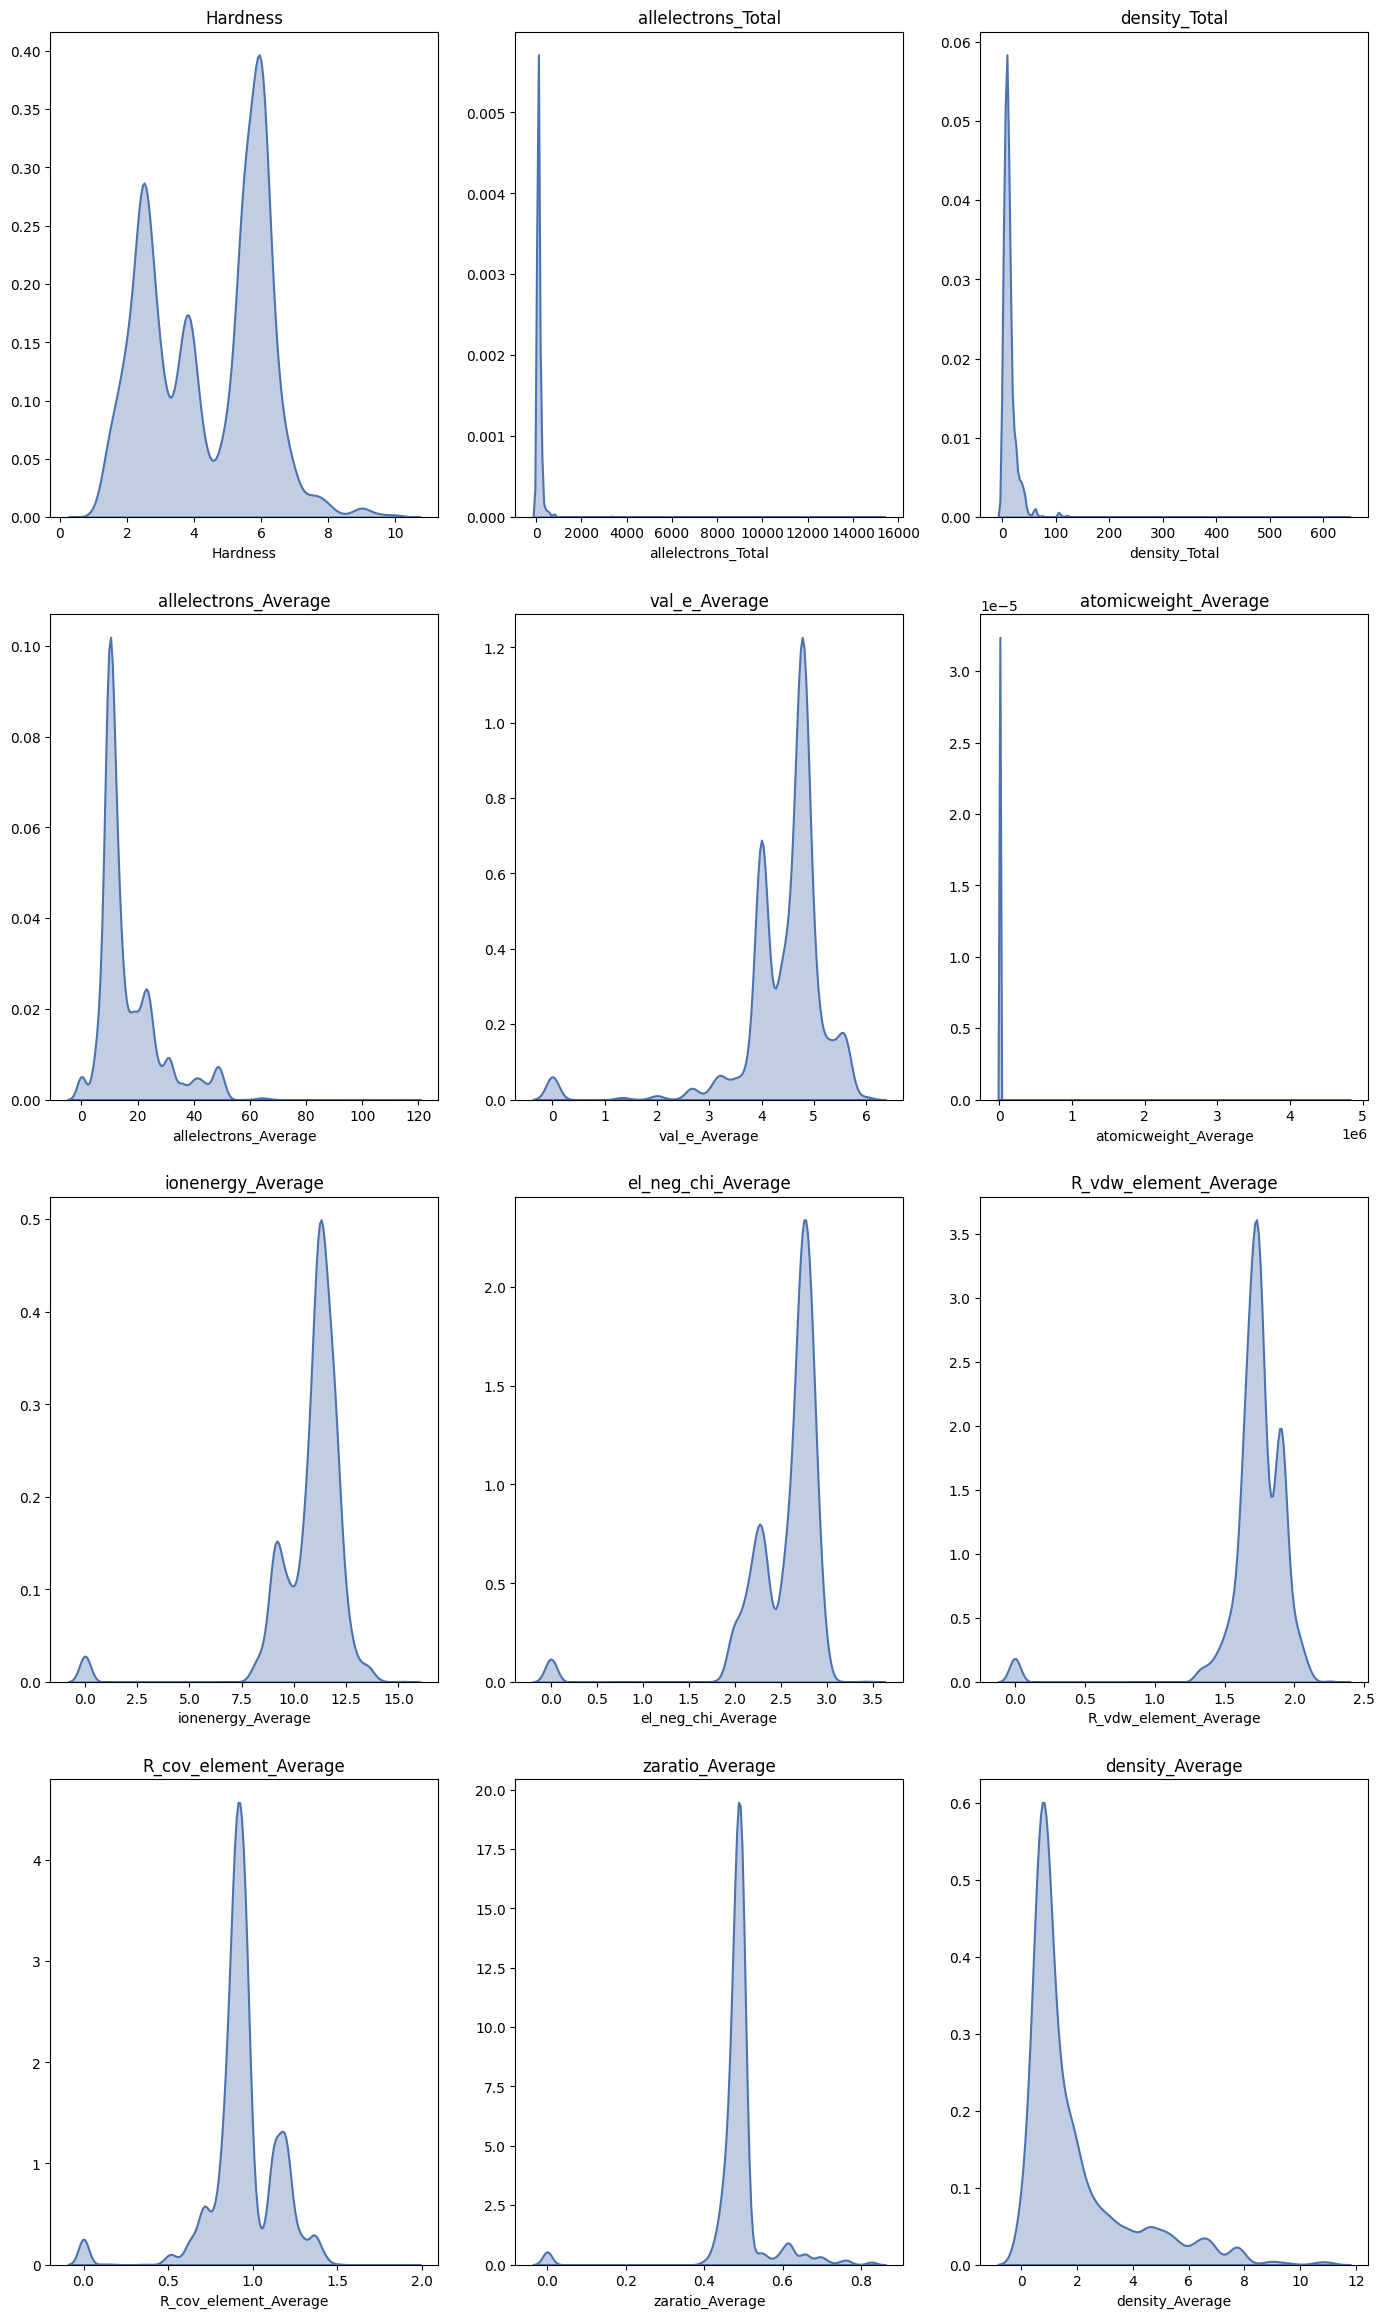

In [28]:
fig, axes = plt.subplots(4, 3, figsize=(17, 29))

for ax, col in zip(axes.flatten(), num_cols):
    sns.kdeplot(data_viz.loc[:, col].dropna(),
        ax=ax, 
        fill=True, 
        alpha=0.35, 
        color="#4C72B0", 
        linewidth=1.5)
    ax.set_title(col)
    ax.set_ylabel("")

In [39]:
train["ln_allelectrons_Total"] = np.log1p(train["allelectrons_Total"])

<Axes: >

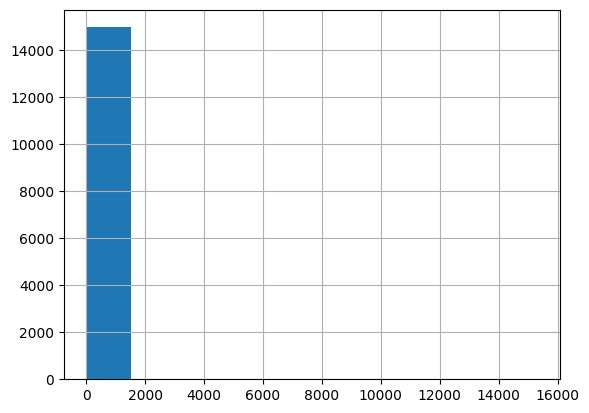

In [41]:
train["allelectrons_Total"].hist()

<Axes: >

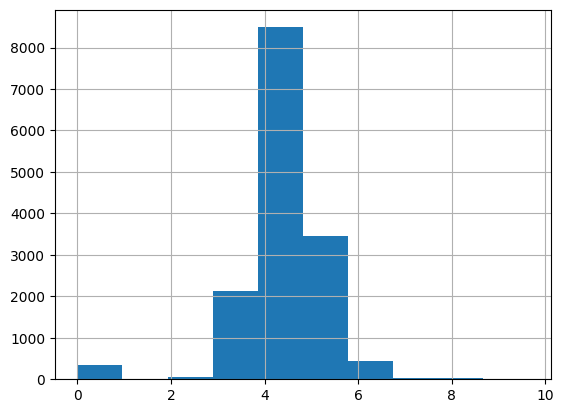

In [42]:
train["ln_allelectrons_Total"].hist()

In [44]:
ln_var = ['allelectrons_Total','density_Total','atomicweight_Average']

In [45]:
for col in ln_var:
    train[f'ln_{col}'] = np.log1p(train[col])
    test[f'ln_{col}'] = np.log1p(test[col])

In [48]:
train_cl = train.drop(columns= ln_var). copy()
test_cl = test.drop(columns=ln_var).copy()

In [49]:
num_cols_cl = train_cl.drop(columns=["id"]).select_dtypes(include="number").columns.to_list()

In [50]:
data_viz_cl = train_cl.drop(columns = ["id"])

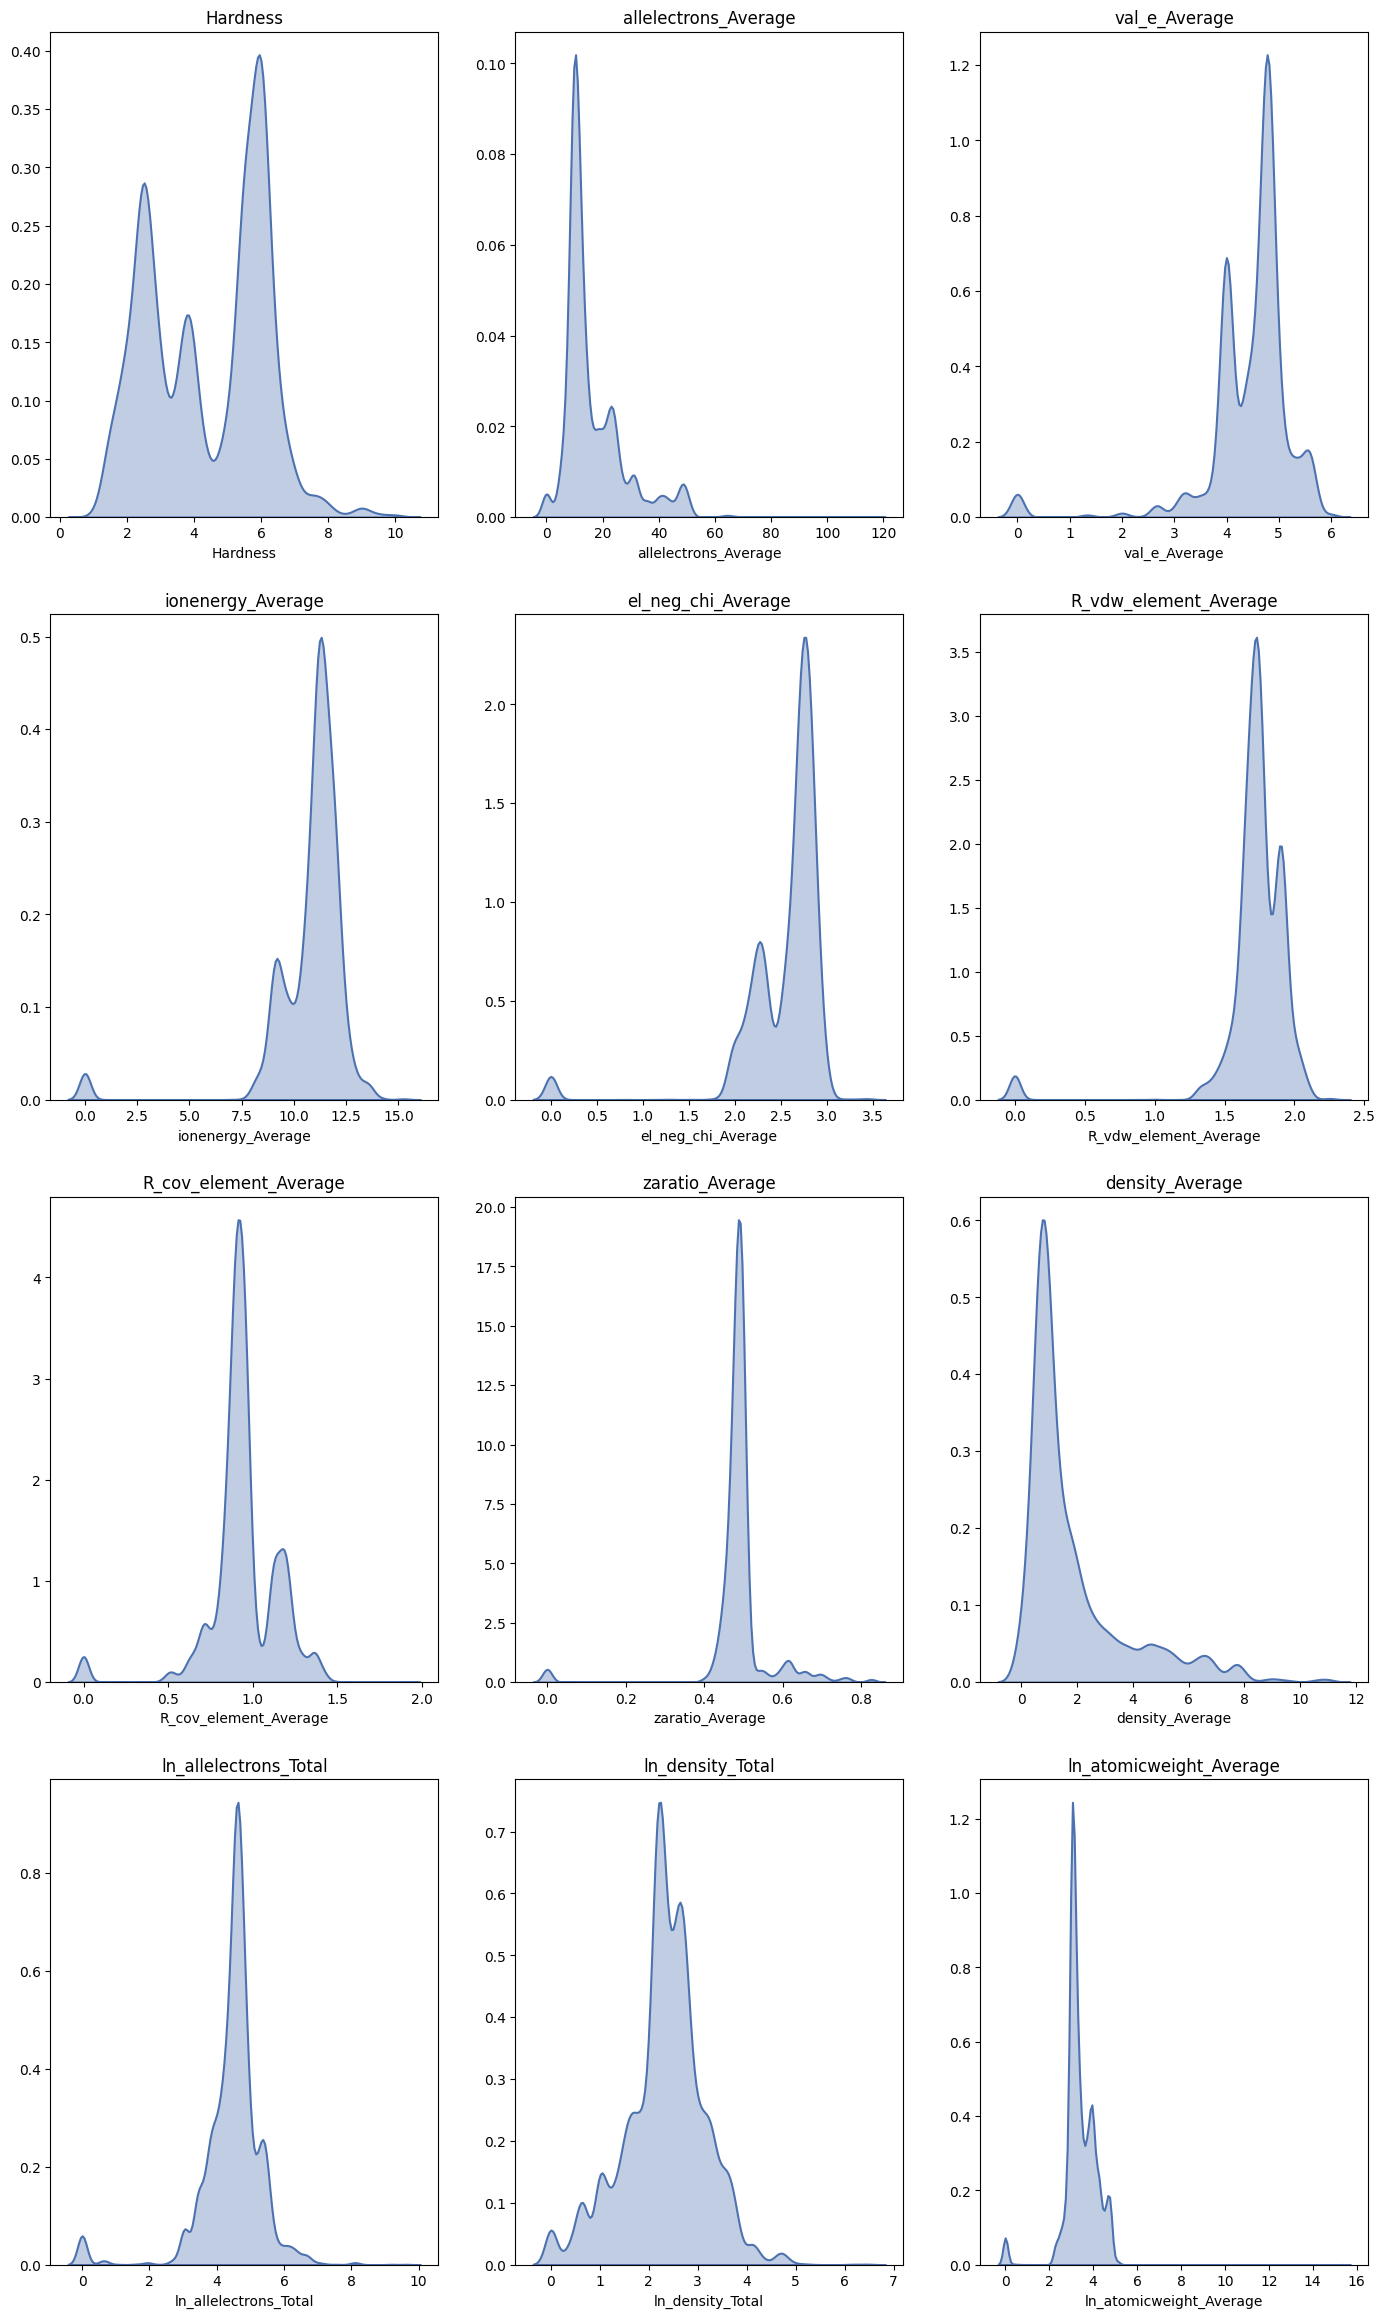

In [51]:
fig, axes = plt.subplots(4, 3, figsize=(17, 29))

for ax, col in zip(axes.flatten(), num_cols_cl):
    sns.kdeplot(data_viz_cl.loc[:, col].dropna(),
        ax=ax, 
        fill=True, 
        alpha=0.35, 
        color="#4C72B0", 
        linewidth=1.5)
    ax.set_title(col)
    ax.set_ylabel("")